# A20 在常规模拟中最好的方案，遇到变化还可靠吗？

比较固定资源与带备用的策略。正常、需求抬升、厚尾、相关故障分别构成测试情景，输出成本、尾部风险和服务目标的全部通过率。

先修：基础课 Python、NumPy、实验评价

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


### 1. 写出可手算的策略评价函数
政策事前决定常备和备用人数。假设每时段服务开始前已观察该批待处理需求和故障，然后从已预约备用池中启用人员；这不是提前知道未来到达。先检查零需求和容量上限。服务目标是本次事件所有时段都满足容量。

In [2]:
import numpy as np
import pandas as pd

def evaluate_policy(policy, demand, failure):
    base, reserve = policy
    available = np.maximum(0, base - failure)
    activate = np.minimum(reserve, np.maximum(0, np.ceil(demand / 10) - available))
    shortage = np.maximum(0, demand - 10 * (available + activate))
    cost = base * 12 + reserve * 3 + activate * 8 + shortage * 15
    return (cost, shortage)
assert evaluate_policy((2, 0), np.array([0]), np.array([0]))[0][0] == 24
assert evaluate_policy((2, 0), np.array([30]), np.array([0]))[1][0] == 10
policies = {'lean': (10, 0), 'reserve': (10, 3), 'large': (13, 0)}

### 2. 留出多类机制变化
每个情景有100个活动日，每日8个时段。相关故障中，一次事件影响同一天的所有时段。用共享场景比较策略，但不给策略在这些最终情景上调参。

In [3]:
def scenario(kind, seed):
    rng = np.random.default_rng(seed)
    d = rng.poisson(85, (100, 8)).astype(float)
    f = rng.binomial(10, 0.03, (100, 8))
    if kind == 'higher':
        d += 25
    if kind == 'heavy_tail':
        d += rng.binomial(1, 0.05, (100, 8)) * 80
    if kind == 'correlated_failure':
        f += rng.binomial(1, 0.15, (100, 1)) * 4
    return (d, f)
records = []
paired = {}
for i, kind in enumerate(['normal', 'higher', 'heavy_tail', 'correlated_failure']):
    d, f = scenario(kind, 2000 + i)
    for name, policy in policies.items():
        c, s = evaluate_policy(policy, d, f)
        daily = c.sum(axis=1)
        paired[kind, name] = daily
        records.append({'scenario': kind, 'policy': name, 'mean_cost': float(daily.mean()), 'p95_daily_cost': float(np.quantile(daily, 0.95)), 'all_periods_pass_rate': float(np.mean((s == 0).all(axis=1))), 'period_pass_rate': float(np.mean(s == 0))})
results = pd.DataFrame(records)

### 3. 成对差值区间与情景遗憾
先按天聚合，再对天重采样，避免把同一天相关的时段当作独立样本。这里区间估计的是该仿真机制下的平均成本差，不是现实效果保证。

In [4]:
rng = np.random.default_rng(20)
differences = paired['normal', 'reserve'] - paired['normal', 'lean']
boot = np.array([rng.choice(differences, len(differences), replace=True).mean() for _ in range(500)])
interval = np.quantile(boot, [0.025, 0.975])
results['scenario_regret'] = results.mean_cost - results.groupby('scenario').mean_cost.transform('min')
results.to_csv(OUT_DIR / 'stress_matrix.csv', index=False)
pivot = results.pivot(index='scenario', columns='policy', values='mean_cost')
pivot = pivot.rename(index={'normal': '常态', 'higher': '需求抬升', 'heavy_tail': '厚尾需求', 'correlated_failure': '相关故障'}, columns={'lean': '精简配置', 'reserve': '预留备用', 'large': '常备增员'})
pivot.plot.bar()
plt.xlabel('压力情景')
plt.ylabel('平均每日成本（元，8时段合计）')
plt.xticks(rotation=0)
plt.legend(title='策略')
plt.tight_layout()
plt.savefig(OUT_DIR / 'stress.png')
plt.close()

### 4. 说明风险偏好与边界
平均成本、尾部风险、全部通过率可能冲突。不要把满足95%时段写成95%的活动全部可行。本例是固定候选的压力测试，尚未对未观测极端情景提供保证。

In [5]:
metrics = {'cost_unit': '元/活动日（8时段合计）', 'normal_reserve_minus_lean_mean': float(differences.mean()), 'bootstrap_95_interval': interval.tolist(), 'stress_results': results.to_dict('records')}
recommendation = '请依据 stress_matrix.csv 同时比较平均成本、95%分位日成本与整日全通过率。若所有时段都必须有容量，优先检查 all_periods_pass_rate；表中出现缺口的方案不能因平均得分高就称为满足硬约束。'

### 保存可核验的证据
把指标写入 JSON，并用本次输出形成有条件的建议。json.dumps 把字典变成文本；不会替你判断方案是否适合现实。

In [6]:
import json
(OUT_DIR / 'metrics.json').write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding='utf-8')
(OUT_DIR / '决策建议.md').write_text('# 本次计算的决策建议\n\n' + recommendation + '\n\n## 实际指标\n```json\n' + json.dumps(metrics, ensure_ascii=False, indent=2) + '\n```\n\n这些结论只适用于本例显式假设；目标权重和风险偏好由人决定。', encoding='utf-8')
print(metrics)

{'cost_unit': '元/活动日（8时段合计）', 'normal_reserve_minus_lean_mean': -4.17, 'bootstrap_95_interval': [-23.15825, 14.013749999999991], 'stress_results': [{'scenario': 'normal', 'policy': 'lean', 'mean_cost': 1045.05, 'p95_daily_cost': 1216.5, 'all_periods_pass_rate': 0.37, 'period_pass_rate': 0.88, 'scenario_regret': 4.169999999999845}, {'scenario': 'normal', 'policy': 'reserve', 'mean_cost': 1040.88, 'p95_daily_cost': 1064.0, 'all_periods_pass_rate': 1.0, 'period_pass_rate': 1.0, 'scenario_regret': 0.0}, {'scenario': 'normal', 'policy': 'large', 'mean_cost': 1248.0, 'p95_daily_cost': 1248.0, 'all_periods_pass_rate': 1.0, 'period_pass_rate': 1.0, 'scenario_regret': 207.1199999999999}, {'scenario': 'higher', 'policy': 'lean', 'mean_cost': 2585.25, 'p95_daily_cost': 3316.5, 'all_periods_pass_rate': 0.0, 'period_pass_rate': 0.1175, 'scenario_regret': 1400.26}, {'scenario': 'higher', 'policy': 'reserve', 'mean_cost': 1184.99, 'p95_daily_cost': 1342.6499999999999, 'all_periods_pass_rate': 0.59, '

## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

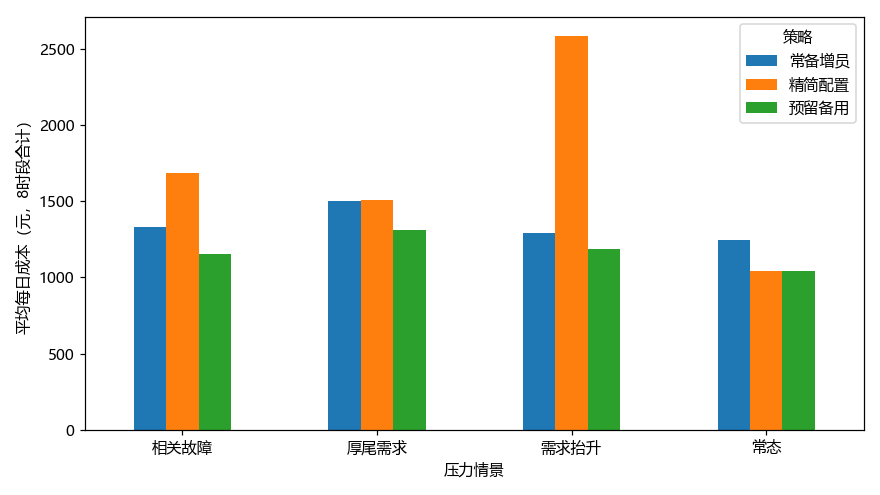

In [7]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
没有真实记录时只能做条件推演。测试情景不能覆盖未知的一切。图中95%分位是成本分布的分位数，与均值估计区间不是一回事。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。